# 🧬 Analyse des Résistances Antimicrobiennes (AMR), Tendance Statistique Nationale & Forecasting

Ce notebook regroupe en Python pur l'intégralité de **l'analyse descriptive et inférentielle des résistances aux antibiotiques** et de la **modélisation prédictive (Forecasting mensuel et trimestriel)** issue de la surveillance GLASS :

1. **Chargement et filtrage des données** (`data.parquet` / bases issues de la déduplication `df_glass`, `df_14j`, `df_30j`, `df_365j`)
2. **Analyse descriptive des résistances (`%R`) et Analyse Statistique de la Tendance Nationale** :
   - Effectifs et proportions par couple Bactérie × Antibiotique (`R`, `S`, `I`, `Testés (S/I/R)`, `%R = R / (S + I + R)`)
   - Matrice / Carte de chaleur **Bactérie × Antibiotique** avec seuils de vigilance clinique (`< 20 %`, `20–50 %`, `> 50 %`)
   - Évolution annuelle descriptive de `%R` et des volumes testés
   - **Test statistique de tendance nationale mensuelle** par régression binomiale groupée ($R_t$ succès sur $N_t = S_t + I_t + R_t$ essais), diagnostics de surdispersion ($\hat{\phi}$) et d'autocorrélation (Ljung–Box / lag-1), erreurs-types robustes adaptatives (Quasi-Binomial / HAC Newey–West) et correction des tests multiples par **Benjamini–Hochberg (FDR)**
   - Comparaison descriptive des taux de résistance par **Hôpital** et par **Service**
3. **Forecasting Mensuel** (`forecasting.py`)
4. **Forecasting Trimestriel National & Comparaison de Méthodes** (`quarterly_forecasting.py`)

In [1]:
import warnings
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from dashboard_data import (
    ALL_ANTIBIOTICS,
    ALL_BACTERIA,
    HOSPITAL_COLUMN,
    ORGANISM_COLUMN,
    WARD_COLUMN,
    YEAR_COLUMN,
    build_deduplicated_databases,
    build_monthly_cube,
    compare_monthly_methods_for_pair,
    compute_resistance_summary,
    fill_missing_label,
    filter_amr_data,
    format_bacterium,
    format_label,
    get_monthly_resistance_series,
    load_source_data,
    pooled_antibiotic_counts,
    run_monthly_forecast,
    style_resistance,
    MIN_TREND_MONTHS,
    analyze_all_national_trends,
    build_national_monthly_sir_cube,
    estimate_national_monthly_trend,
    get_national_monthly_sir_series,
)
from forecasting import (
    optimize_holt_parameters,
    optimize_holt_winters_parameters,
)
from quarterly_forecasting import (
    ForecastConfig,
    aggregate_quarterly_counts,
    forecast_quarterly,
)

warnings.filterwarnings("ignore", category=UserWarning)
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)

---
## 1. Choix de la Base Dédupliquée, Chargement et Filtrage du Périmètre d'Étude

Vous pouvez préciser au début du notebook quelle base issue de la déduplication (`amr_deduplication.py`) utiliser pour toute l'analyse des résistances et le forecasting :
- `"df_glass"` (ou directement le DataFrame `df_glass`) : déduplication annuelle **WHO GLASS** (avec priorité LCR sur Sang le même jour)
- `"df_14j"` (ou `df_14j`) : déduplication par épisode de **14 jours**
- `"df_30j"` (ou `df_30j`) : déduplication par épisode de **30 jours**
- `"df_365j"` (ou `df_365j`) : déduplication par épisode de **365 jours**
- `"raw"` : base complète brute sans déduplication (`data.parquet`)
- ou le chemin vers un fichier `.parquet` pré-enregistré.

In [2]:
# ==============================================================================
# PARAMÈTRE PRINCIPAL : CHOIX DE LA BASE DE DONNÉES (ISSUE DE LA DÉDUPLICATION)
# ==============================================================================
# Valeurs possibles : "df_glass", "df_14j", "df_30j", "df_365j", "raw"
# (ou directement un DataFrame : df_glass, df_14j, df_30j, df_365j)
DATASET_CHOICE = "df_glass"
DATA_PARQUET_PATH = "data.parquet"
ELIGIBILITY_SCOPE = "all_eligible"  # "all_eligible" (7 origines harmonisées) ou "strict_glass"

# Construction / récupération des 4 DataFrames dédupliqués en mémoire
DEDUP_DATABASES = build_deduplicated_databases(
    DATA_PARQUET_PATH, eligibility_scope=ELIGIBILITY_SCOPE, verbose=False
)
df_amr = DEDUP_DATABASES["df_amr"]
df_glass = DEDUP_DATABASES["df_glass"]
df_14j = DEDUP_DATABASES["df_14j"]
df_30j = DEDUP_DATABASES["df_30j"]
df_365j = DEDUP_DATABASES["df_365j"]

print("Bases dédupliquées disponibles en mémoire :")
for name in ["df_glass", "df_14j", "df_30j", "df_365j"]:
    marker = " <-- [ACTIVE]" if str(DATASET_CHOICE) == name else ""
    print(f"  - {name:<8} : {len(DEDUP_DATABASES[name]):>7,} isolats retenus{marker}")

# Chargement de la base active pour l'analyse des résistances et le forecasting
SOURCE, SOURCE_RECORDS, ANTIBIOTIC_COLUMNS = load_source_data(
    DATA_PARQUET_PATH,
    dataset_choice=DATASET_CHOICE,
    eligibility_scope=ELIGIBILITY_SCOPE,
)

print("\n=== BASE SÉLECTIONNÉE POUR L'ANALYSE ===")
print(f"Base active                       : {SOURCE.attrs.get('dataset_label', DATASET_CHOICE)}")
print(f"Isolats uniques retenus (row_uid) : {len(SOURCE_RECORDS):,}")
print(f"Lignes de tests d'antibiogramme   : {len(SOURCE):,}")
print(f"Bactéries distinctes              : {SOURCE_RECORDS[ORGANISM_COLUMN].nunique()}")
print(f"Antibiotiques distincts           : {len(ANTIBIOTIC_COLUMNS)}")
print(f"Années couvertes                  : {sorted(y for y in SOURCE_RECORDS[YEAR_COLUMN].unique() if y)}")

AMR: Setting up R environment and AMR datasets...


AMR: Done.


Bases dédupliquées disponibles en mémoire :
  - df_glass :  86,057 isolats retenus <-- [ACTIVE]
  - df_14j   :  86,297 isolats retenus
  - df_30j   :  86,250 isolats retenus
  - df_365j  :  86,060 isolats retenus



=== BASE SÉLECTIONNÉE POUR L'ANALYSE ===
Base active                       : WHO GLASS (Annuel) (86,057 isolats)
Isolats uniques retenus (row_uid) : 86,057
Lignes de tests d'antibiogramme   : 1,729,174
Bactéries distinctes              : 21
Antibiotiques distincts           : 76
Années couvertes                  : ['2019', '2020', '2021', '2022', '2023', '2024', '2025']


In [3]:
# Paramètres de filtrage du périmètre (laisser None pour tout inclure)
FILTER_YEARS = None        # ex: ["2021", "2022", "2023", "2024"]
FILTER_HOSPITALS = None    # ex: ["CENTRE NATIONAL DE GREFFE DE MOELLE OSSEUSE"]
FILTER_WARDS = None        # ex: ["Hématologie"]
FILTER_SPECIMENS = None    # ex: ["Hémoculture", "Urine"]
FILTER_ORGANISMS = None    # ex: ["Klebsiella pneumoniae", "Escherichia coli"]
FILTER_ANTIBIOTICS = None  # ex: ["cefotaxime", "ciprofloxacine", "imipeneme"]

filtered_source, filtered_records, scope_antibiotics = filter_amr_data(
    SOURCE,
    SOURCE_RECORDS,
    years=FILTER_YEARS,
    hospitals=FILTER_HOSPITALS,
    wards=FILTER_WARDS,
    specimens=FILTER_SPECIMENS,
    organisms=FILTER_ORGANISMS,
    antibiotics=FILTER_ANTIBIOTICS,
)

print(f"Périmètre actif : {len(filtered_records):,} enregistrements | {len(scope_antibiotics)} antibiotiques")

Périmètre actif : 86,057 enregistrements | 76 antibiotiques


---
## 2. Analyse des Résistances et Tendances Descriptives

### 2.1 Tableau des effectifs (`S`, `I`, `R`, `Testés (S/I/R)`) et taux de résistance `%R`
Le taux de résistance est défini par :
$$\%R = \frac{R}{S + I + R} \times 100$$
Les couples ayant moins de `LOW_COUNT_THRESHOLD` résultats interprétables sont signalés (« Effectif faible ») sans être exclus.

In [4]:
LOW_COUNT_THRESHOLD = 30

resistance_table, resistance_matrix = compute_resistance_summary(
    filtered_source,
    records_frame=filtered_records,
    antibiotic_columns=scope_antibiotics,
    low_count_threshold=LOW_COUNT_THRESHOLD,
)

# Affichage des couples les plus testés
display(
    resistance_table.sort_values("Testés (S/I/R)", ascending=False)
    .head(25)
    .reset_index(drop=True)
)

,Bactérie,Antibiotique,Résistants (R),Testés (S/I/R),S,I,%R,Signalement d’effectif
0,Escherichia coli,Ciprofloxacin,6516,13548,6904,128,48.10,Effectif au-dessus du seuil
1,Escherichia coli,Gentamicin,7231,12640,5407,2,57.21,Effectif au-dessus du seuil
2,Escherichia coli,Amikacin,3365,12269,8870,34,27.43,Effectif au-dessus du seuil
3,Escherichia coli,Amoxicillin/clavulanic acid,7567,12155,4560,28,62.25,Effectif au-dessus du seuil
4,Escherichia coli,Cefotaxime,4086,11854,7749,19,34.47,Effectif au-dessus du seuil
5,Escherichia coli,Ceftazidime,3770,11658,7765,123,32.34,Effectif au-dessus du seuil
6,Escherichia coli,Fosfomycin,1280,10006,8725,1,12.79,Effectif au-dessus du seuil
7,Escherichia coli,Ticarcillin,6100,8988,2874,14,67.87,Effectif au-dessus du seuil
8,Escherichia coli,Trimethoprim/sulfamethoxazole,4050,8899,4838,11,45.51,Effectif au-dessus du seuil
9,Escherichia coli,Tigecycline,822,8799,7967,10,9.34,Effectif au-dessus du seuil


### 2.2 Carte de chaleur (Matrice Bactérie × Antibiotique `%R`)
Code couleur médical :
- **Vert** (`< 20 %`) : résistance faible
- **Orange** (`20 % – 50 %`) : résistance modérée
- **Rouge** (`> 50 %`) : résistance élevée / critique

In [5]:
# Affichage stylisé de la matrice Bactérie × Antibiotique
styled_matrix = resistance_matrix.style.format("{:.1f}%", na_rep="—").map(style_resistance)
display(styled_matrix)

Antibiotique,Amikacin,Amoxicillin,Amoxicillin/clavulanic acid,Ampicillin,Ampicillin/sulbactam,Azithromycin,Aztreonam,Benzylpenicillin,Cefadroxil,Cefalexin,Cefalotin,Cefepime,Cefixime,Cefotaxime,Cefotaxime/clavulanic acid,Cefoxitin,Cefoxitin (screening test),Cefpirome,Cefpodoxime,Ceftaroline,Ceftazidime,Ceftazidime/clavulanic acid,Ceftriaxone,Cefuroxime,Cefuroxime axetil,Chloramphenicol,Ciprofloxacin,Clarithromycin,Clindamycin,Clindamycin (inducible resistance test),Colistin,Daptomycin,Doripenem,Doxycycline,Ertapenem,Erythromycin,Fosfomycin,Fusidic acid,Gentamicin,"Gentamicin (high-level, synergy)",Imipenem,Kanamycin,Levofloxacin,Lincomycin,Linezolid,Mecillinam,Meropenem,Metronidazole,Minocycline,Moxifloxacin,Mupirocin,Nalidixic acid,Netilmicin,Nitrofurantoin,Norfloxacin,Ofloxacin,Oxacillin,Pefloxacin,Piperacillin,Piperacillin/tazobactam,Pristinamycin,Quinupristin/dalfopristin,Rifampicin,Streptomycin,"Streptomycin (high-level, synergy)",Teicoplanin,Telithromycin,Temocillin,Tetracycline,Ticarcillin,Ticarcillin/clavulanic acid,Tigecycline,Tobramycin,Trimethoprim,Trimethoprim/sulfamethoxazole,Vancomycin
Bactérie,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
Acinetobacter baumannii,93.4%,100.0%,100.0%,100.0%,—,—,100.0%,—,—,96.8%,100.0%,85.8%,100.0%,96.2%,—,100.0%,—,—,—,—,92.0%,—,100.0%,100.0%,—,93.8%,97.3%,—,—,0.0%,49.1%,—,—,70.8%,100.0%,—,100.0%,—,97.3%,—,96.7%,—,89.2%,—,—,100.0%,99.0%,—,66.7%,100.0%,—,100.0%,85.0%,100.0%,—,100.0%,100.0%,—,93.8%,89.7%,—,—,100.0%,—,—,—,—,100.0%,83.4%,90.2%,87.3%,70.8%,83.4%,—,61.7%,—
Enterobacter cloacae,35.2%,100.0%,99.2%,96.7%,—,—,12.8%,100.0%,—,71.6%,100.0%,45.9%,31.1%,54.0%,16.7%,97.5%,—,—,—,—,52.4%,0.0%,8.7%,45.3%,—,9.8%,39.7%,—,94.5%,25.0%,69.3%,—,0.0%,85.7%,40.6%,100.0%,73.9%,—,72.8%,—,15.7%,0.0%,48.6%,—,0.0%,30.0%,0.0%,—,0.0%,100.0%,—,12.6%,4.5%,77.7%,11.4%,9.9%,—,—,21.7%,52.6%,0.0%,—,—,—,100.0%,0.0%,—,10.4%,13.6%,26.6%,24.6%,21.4%,9.1%,0.0%,25.7%,0.0%
Enterococcus faecalis,100.0%,0.0%,0.0%,24.2%,—,—,—,28.2%,—,29.7%,100.0%,100.0%,—,100.0%,—,—,—,—,—,—,—,—,—,100.0%,—,16.5%,28.6%,—,98.7%,—,—,0.0%,—,—,100.0%,64.7%,1.4%,0.0%,19.7%,—,1.8%,33.3%,21.8%,100.0%,22.9%,—,—,—,—,33.3%,—,—,61.5%,3.5%,32.9%,100.0%,100.0%,—,0.0%,—,74.1%,97.5%,45.6%,41.5%,52.3%,1.9%,—,100.0%,75.6%,—,0.0%,23.6%,—,—,49.8%,39.2%
Enterococcus faecium,100.0%,100.0%,—,99.6%,—,—,—,95.8%,—,71.9%,100.0%,100.0%,—,100.0%,—,—,—,—,—,—,—,—,—,100.0%,—,0.0%,100.0%,—,89.7%,—,—,0.0%,—,—,100.0%,93.5%,11.1%,0.0%,68.6%,—,98.8%,66.7%,82.3%,100.0%,18.5%,—,100.0%,—,—,100.0%,—,—,0.0%,62.9%,87.0%,—,—,—,100.0%,—,71.4%,52.2%,92.1%,75.0%,82.0%,29.7%,—,—,33.3%,—,—,14.1%,—,—,47.9%,66.9%
Escherichia coli,27.4%,92.7%,62.2%,69.9%,20.0%,—,10.5%,—,0.0%,26.1%,29.4%,34.6%,16.8%,34.5%,0.0%,5.2%,—,—,0.0%,—,32.3%,0.0%,13.4%,15.4%,18.8%,10.0%,48.1%,—,18.1%,10.0%,1.6%,—,0.0%,37.0%,4.8%,—,12.8%,—,57.2%,—,1.0%,10.7%,26.8%,—,0.0%,39.9%,1.6%,—,11.1%,28.6%,—,31.3%,4.6%,10.4%,28.9%,23.8%,—,43.6%,70.8%,49.7%,—,—,—,—,—,—,—,7.0%,44.0%,67.9%,32.8%,9.3%,10.6%,40.0%,45.5%,—
Haemophilus influenzae,36.4%,55.0%,92.0%,66.2%,—,—,—,68.9%,—,100.0%,—,15.0%,—,74.2%,—,100.0%,—,—,—,—,0.0%,—,2.0%,39.3%,—,12.1%,79.3%,—,25.0%,—,0.0%,—,—,14.3%,23.5%,19.4%,—,—,—,—,20.9%,—,82.8%,100.0%,—,—,0.0%,—,0.0%,16.3%,—,24.6%,0.0%,—,—,30.1%,100.0%,—,44.4%,0.0%,—,—,76.8%,—,—,—,—,—,23.2%,100.0%,—,0.0%,—,—,74.2%,—
Klebsiella oxytoca,5.3%,—,25.0%,97.3%,—,—,13.9%,—,—,25.7%,—,13.3%,—,18.4%,—,10.8%,—,—,—,—,14.7%,—,11.5%,33.3%,—,7.1%,22.7%,—,—,—,100.0%,—,—,—,2.3%,—,23.3%,—,12.3%,—,2.7%,—,20.0%,—,—,—,—,—,—,—,—,25.0%,—,18.2%,0.0%,30.0%,—,34.9%,—,—,—,—,—,—,—,—,—,0.0%,—,94.7%,28.0%,—,15.3%,—,23.0%,—
Klebsiella pneumoniae,48.8%,99.9%,72.5%,99.3%,66.7%,—,35.1%,—,—,47.6%,41.1%,68.5%,38.1%,70.2%,0.0%,23.9%,—,—,50.0%,—,69.8%,0.0%,22.5%,38.1%,30.0%,17.6%,63.4%,—,39.2%,57.6%,23.4%,—,0.0%,39.0%,53.6%,0.0%,77.4%,—,71.3%,—,39.2%,37.5%,38.4%,—,0.0%,49.6%,28.6%,—,55.6%,80.0%,—,33.6%,19.3%,72.0%,35.1%,35.3%,—,69.8%,95.4%,70.1%,—,—,0.0%,—,—,0.0%,—,12.7%,34.0%,99.3%,48.0%,30.6%,27.6%,33.3%,52.8%,0.0%
Ne

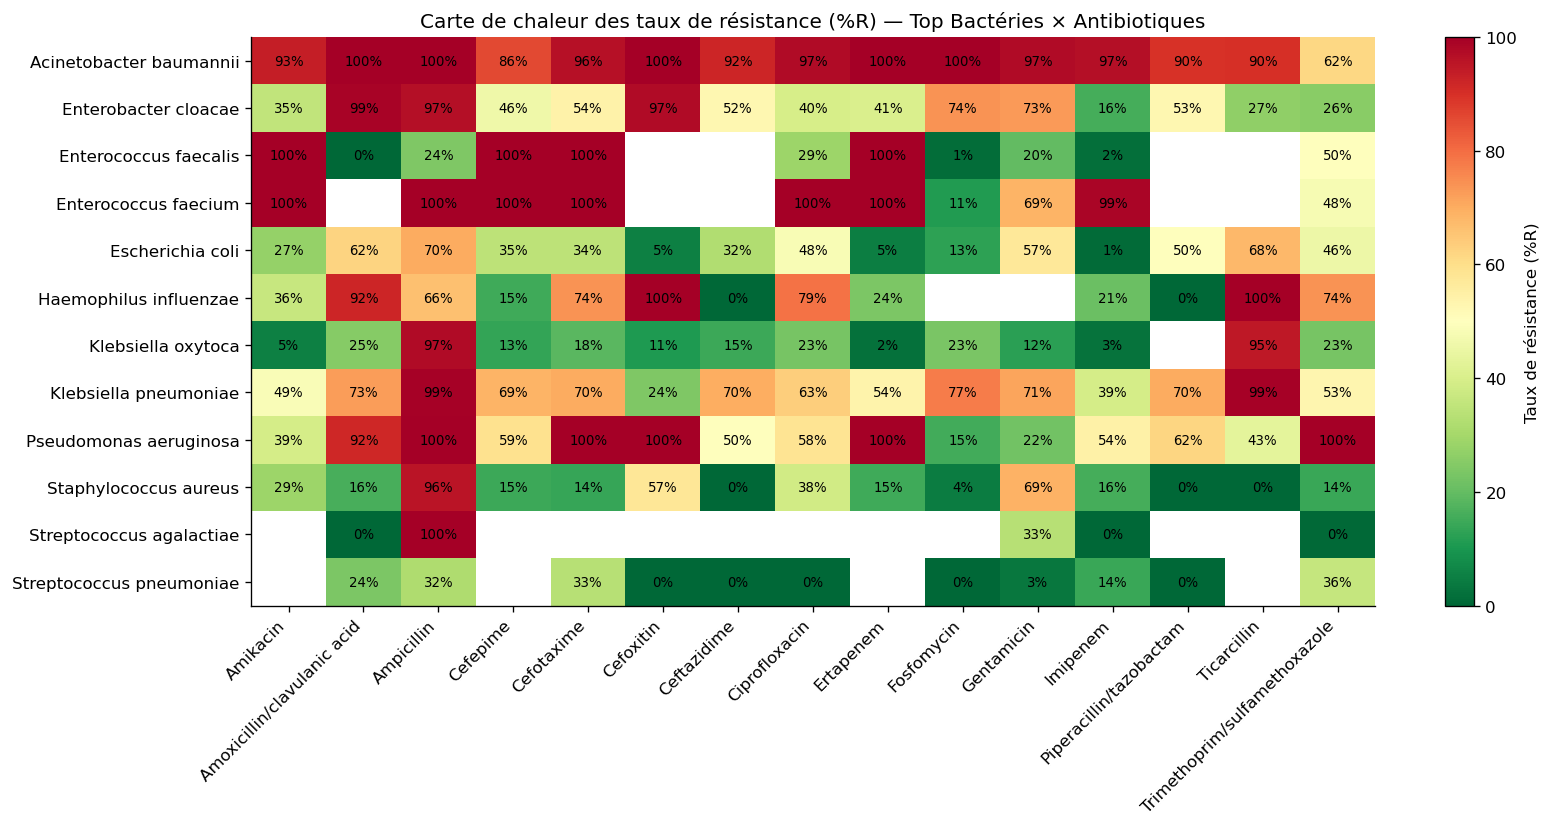

In [6]:
# Visualisation graphique de la carte de chaleur pour les principales bactéries et antibiotiques
top_bacteria = (
    resistance_table.groupby("Bactérie")["Testés (S/I/R)"]
    .sum()
    .sort_values(ascending=False)
    .head(12)
    .index
)
top_abx = (
    resistance_table.groupby("Antibiotique")["Testés (S/I/R)"]
    .sum()
    .sort_values(ascending=False)
    .head(15)
    .index
)
sub_matrix = resistance_matrix.loc[
    resistance_matrix.index.intersection(top_bacteria),
    resistance_matrix.columns.intersection(top_abx),
]

fig, ax = plt.subplots(figsize=(14, 7))
im = ax.imshow(sub_matrix.values, cmap="RdYlGn_r", aspect="auto", vmin=0, vmax=100)
ax.set_xticks(range(len(sub_matrix.columns)))
ax.set_xticklabels(sub_matrix.columns, rotation=45, ha="right")
ax.set_yticks(range(len(sub_matrix.index)))
ax.set_yticklabels(sub_matrix.index)
ax.set_title("Carte de chaleur des taux de résistance (%R) — Top Bactéries × Antibiotiques")
ax.grid(False)

for i in range(sub_matrix.shape[0]):
    for j in range(sub_matrix.shape[1]):
        val = sub_matrix.iloc[i, j]
        if pd.notna(val):
            ax.text(j, i, f"{val:.0f}%", ha="center", va="center", color="black", fontsize=8)

fig.colorbar(im, ax=ax, label="Taux de résistance (%R)")
plt.tight_layout()
plt.show()

### 2.3 Évolution annuelle de `%R` et des effectifs testés
Sélectionnez une bactérie (ou `ALL_BACTERIA`) et un antibiotique (ou `ALL_ANTIBIOTICS`) pour analyser la dynamique annuelle.

,Année,Résistants (R),Testés (S/I/R),S,I,Série (R / N),%R
0,2019,116,116,0,0,116 / 116,100.00
1,2020,571,598,27,0,571 / 598,95.48
2,2021,570,886,311,5,570 / 886,64.33
3,2022,600,916,310,6,600 / 916,65.50
4,2023,886,1566,670,10,886 / 1566,56.58
5,2024,921,1491,559,11,921 / 1491,61.77
6,2025,1310,1507,197,0,1310 / 1507,86.93


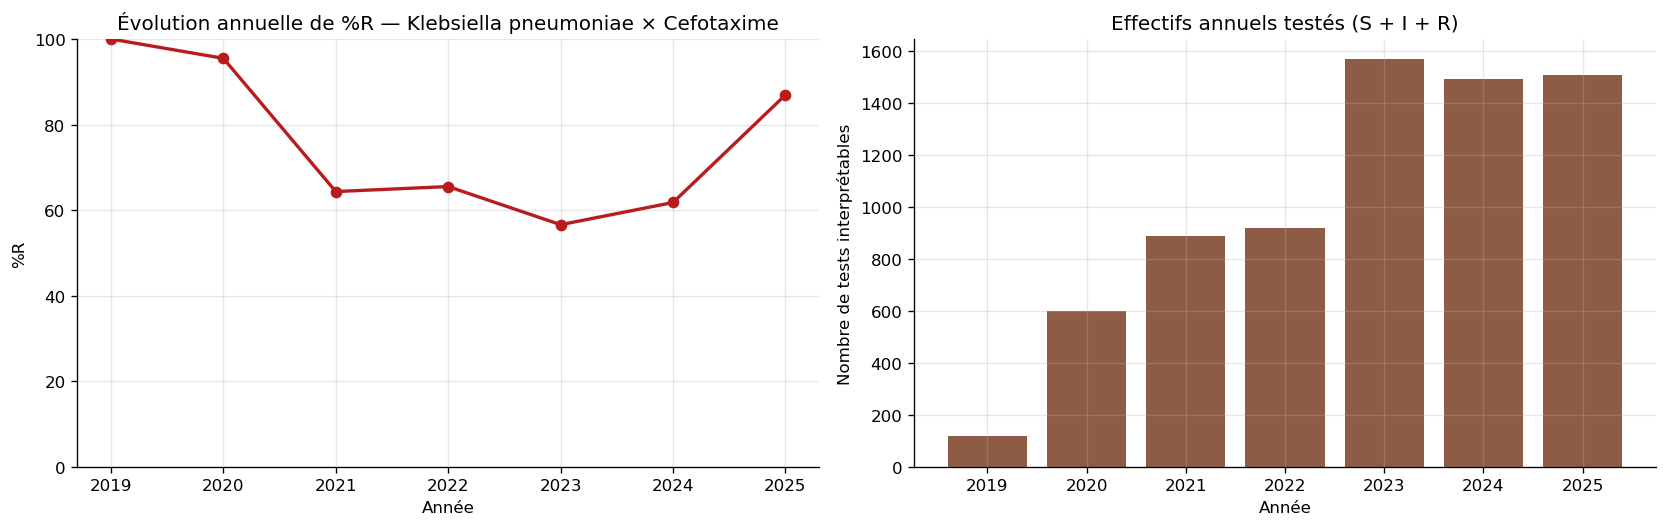

In [7]:
TREND_BACTERIUM = "Klebsiella pneumoniae"  # ou ALL_BACTERIA
TREND_ANTIBIOTIC = "Cefotaxime"            # ou ALL_ANTIBIOTICS

trend_subset = (
    filtered_source
    if TREND_BACTERIUM == ALL_BACTERIA
    else filtered_source.loc[filtered_source[ORGANISM_COLUMN] == TREND_BACTERIUM]
)
trend_records_subset = (
    filtered_records
    if TREND_BACTERIUM == ALL_BACTERIA
    else filtered_records.loc[filtered_records[ORGANISM_COLUMN] == TREND_BACTERIUM]
)
selected_trend_abx = (
    scope_antibiotics
    if TREND_ANTIBIOTIC == ALL_ANTIBIOTICS
    else [a for a in scope_antibiotics if a.casefold() == TREND_ANTIBIOTIC.casefold()]
)

annual_stats = pooled_antibiotic_counts(
    trend_subset,
    [YEAR_COLUMN],
    selected_trend_abx,
    records_frame=trend_records_subset,
)
annual_stats["Année"] = fill_missing_label(annual_stats[YEAR_COLUMN])
annual_stats = annual_stats[annual_stats["Année"] != "Non renseigné"].sort_values("Année").reset_index(drop=True)
annual_stats["Série (R / N)"] = (
    annual_stats["Résistants (R)"].astype(str) + " / " + annual_stats["Testés (S/I/R)"].astype(str)
)

display(annual_stats[["Année", "Résistants (R)", "Testés (S/I/R)", "S", "I", "Série (R / N)", "%R"]])

if not annual_stats.empty and annual_stats["Testés (S/I/R)"].sum() > 0:
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
    axes[0].plot(annual_stats["Année"], annual_stats["%R"], marker="o", linewidth=2, color="#b91c1c")
    axes[0].set_title(f"Évolution annuelle de %R — {format_bacterium(TREND_BACTERIUM)} × {format_label(TREND_ANTIBIOTIC)}")
    axes[0].set_xlabel("Année")
    axes[0].set_ylabel("%R")
    axes[0].set_ylim(0, 100)

    axes[1].bar(annual_stats["Année"], annual_stats["Testés (S/I/R)"], color="#7a3f24", alpha=0.85)
    axes[1].set_title("Effectifs annuels testés (S + I + R)")
    axes[1].set_xlabel("Année")
    axes[1].set_ylabel("Nombre de tests interprétables")
    plt.tight_layout()
    plt.show()

### 2.4 Analyse statistique de la tendance nationale mensuelle (Régression binomiale, Diagnostics & Correction FDR)

#### Méthodologie biostatistique
Les données annuelles ci-dessus ne comportent que 7 points (2019–2025), ce qui est insuffisant pour un test formel de tendance robuste. L'analyse inférentielle principale repose donc sur l'**agrégation nationale mensuelle** de chaque couple `Bactérie × Antibiotique` :
1. **Agrégation nationale exacte ($N_t = S_t + I_t + R_t$) sans imputation des mois manquants :**
   Pour chaque mois observé $t$, on agrège à l'échelle nationale l'ensemble des tests interprétables $N_t = S_t + I_t + R_t$ et le nombre d'isolats résistants $R_t$ ($\%R_t = 100 \times R_t / N_t$). Un mois sans observation ($N_t = 0$) demeure manquant (`NaN`) et n'est **jamais** interprété comme un taux de résistance nul ($0\%$). L'abscisse temporelle $t_{\text{années}}$ est exprimée en **années continues** depuis le premier mois observé ($\Delta t = 1/12\text{ an}$ par mois calendaire).
2. **Modèle de régression binomiale groupée (GLM Binomial à lien logit) :**
   Contrairement à une régression linéaire non pondérée sur les pourcentages mensuels, la régression binomiale modélise directement les effectifs $(R_t, N_t - R_t)$ :
   $$\text{logit}(p_t) = \ln\left(\frac{p_t}{1 - p_t}\right) = \beta_0 + \beta_1 \cdot t_{\text{années}}$$
   où chaque mois pèse proportionnellement à son information binomiale $N_t p_t (1 - p_t)$.
3. **Seuils d'éligibilité explicites (alignés sur les paramètres existants du projet) :**
   - Au moins `MIN_TREND_MONTHS = 6` mois observés avec $N_t > 0$ (même seuil minimal de 6 mois que dans `run_monthly_forecast` et `monthly_binomial_glm_forecasting`).
   - Effectif total cumulé $\sum N_t \ge \text{LOW\_COUNT\_THRESHOLD}$ (`30` tests interprétables, aligné sur `compute_resistance_summary` et `aggregate_quarterly_counts`).
   - Variance non dégénérée ($0 < \sum R_t < \sum N_t$). Si ces conditions ne sont pas réunies, le test n'est pas calculé et le motif exact est rapporté.
4. **Diagnostics des hypothèses et inférence adaptative (aucune p-valeur naïve invalide) :**
   - **Surdispersion ($\hat{\phi}$) :** évaluée par le ratio de Pearson $\hat{\phi} = \chi^2_{\text{Pearson}} / \text{ddl}_{\text{résid}}$ (et test du $\chi^2$ à $\alpha = 0,05$, ou $\hat{\phi} > 1,5$).
   - **Autocorrélation temporelle :** évaluée sur les résidus de Pearson par l'autocorrélation d'ordre 1 ($r_1$ sur paires de mois consécutifs adjacents) et le test de **Ljung–Box**.
   - **Règle de décision pour l'inférence :**
     * Si une **autocorrélation temporelle** est détectée ($p_{\text{Ljung–Box}} < 0,05$ ou $p_{r_1} < 0,05$) : erreurs-types robustes sandwich **HAC de Newey–West** (`cov_type='HAC'`), qui corrigent simultanément l'autocorrélation sérielle et la surdispersion.
     * Si une **surdispersion** est présente sans autocorrélation : modèle **GLM Quasi-Binomial** (`scale='X2'`, multipliant la variance par $\hat{\phi}$).
     * Si ni surdispersion ni autocorrélation ne sont détectées : **GLM Binomial standard (MLE)**.
5. **Double échelle d'interprétation de l'effet :**
   - *Échelle absolue (points de pourcentage par an)* : **Effet marginal annuel moyen (AME)** $\Delta(\%R)/\text{an} = 100 \times \hat{\beta}_1 \sum_t (N_t / N_{\text{tot}}) \hat{p}_t (1 - \hat{p}_t)$ et son IC à 95 % par la méthode Delta.
   - *Échelle du modèle (logit)* : pente $\hat{\beta}_1$ en **log-odds / an** et **Odds Ratio annuel** $\text{OR}_{\text{an}} = \exp(\hat{\beta}_1)$ avec son IC à 95 %.
6. **Correction des tests multiples par Benjamini–Hochberg (FDR) :**
   La correction FDR (`multipletests(method='fdr_bh')`) est appliquée sur la famille clairement définie des $K$ couples `Bactérie × Antibiotique` du périmètre actif ayant un test **effectivement calculé** (en excluant strictement les couples non calculables).

> **Limite d'interprétation épidémiologique :** L'analyse étant agrégée à l'échelle nationale sans ajustement hospitalier, une tendance significative peut refléter à la fois l'évolution biologique réelle de l'antibiorésistance et une modification temporelle de la composition des hôpitaux/services participants (*case-mix*) ou des pratiques de prélèvement et d'antibiogramme ; cette analyse écologique nationale ne permet pas de dissocier ces deux composantes.

=== TENDANCE NATIONALE MENSUELLE : Klebsiella pneumoniae × Cefotaxime ===
Statut du test               : Calculé
Mois observés (N > 0)        : 83 mois (2019-01 -> 2025-12, étendue = 6.92 ans)
Effectif national cumulé R/N : 4,974 / 7,080 (%R global = 70.25%)
Pente absolue (%R pts / an)  : -0.54 pts %/an (IC 95 % : [-4.74 ; +3.66])
Échelle logit (modèle)       : β1 = -0.0260 log-odds/an | OR annuel = 0.974 (IC 95 % : [0.798 ; 1.190])
Taux modélisé début -> fin   : 72.6% -> 68.9%
Diagnostics résiduels        : Dispersion φ = 9.67 (p = 0.0000) | Autocorr. r1 = 0.85 | p Ljung-Box = 0.0000
Méthode d'inférence retenue  : GLM Binomial + HAC Newey–West (surdispersion φ=9.67 & autocorr.)
p-valeur robuste retenue     : 0.7995


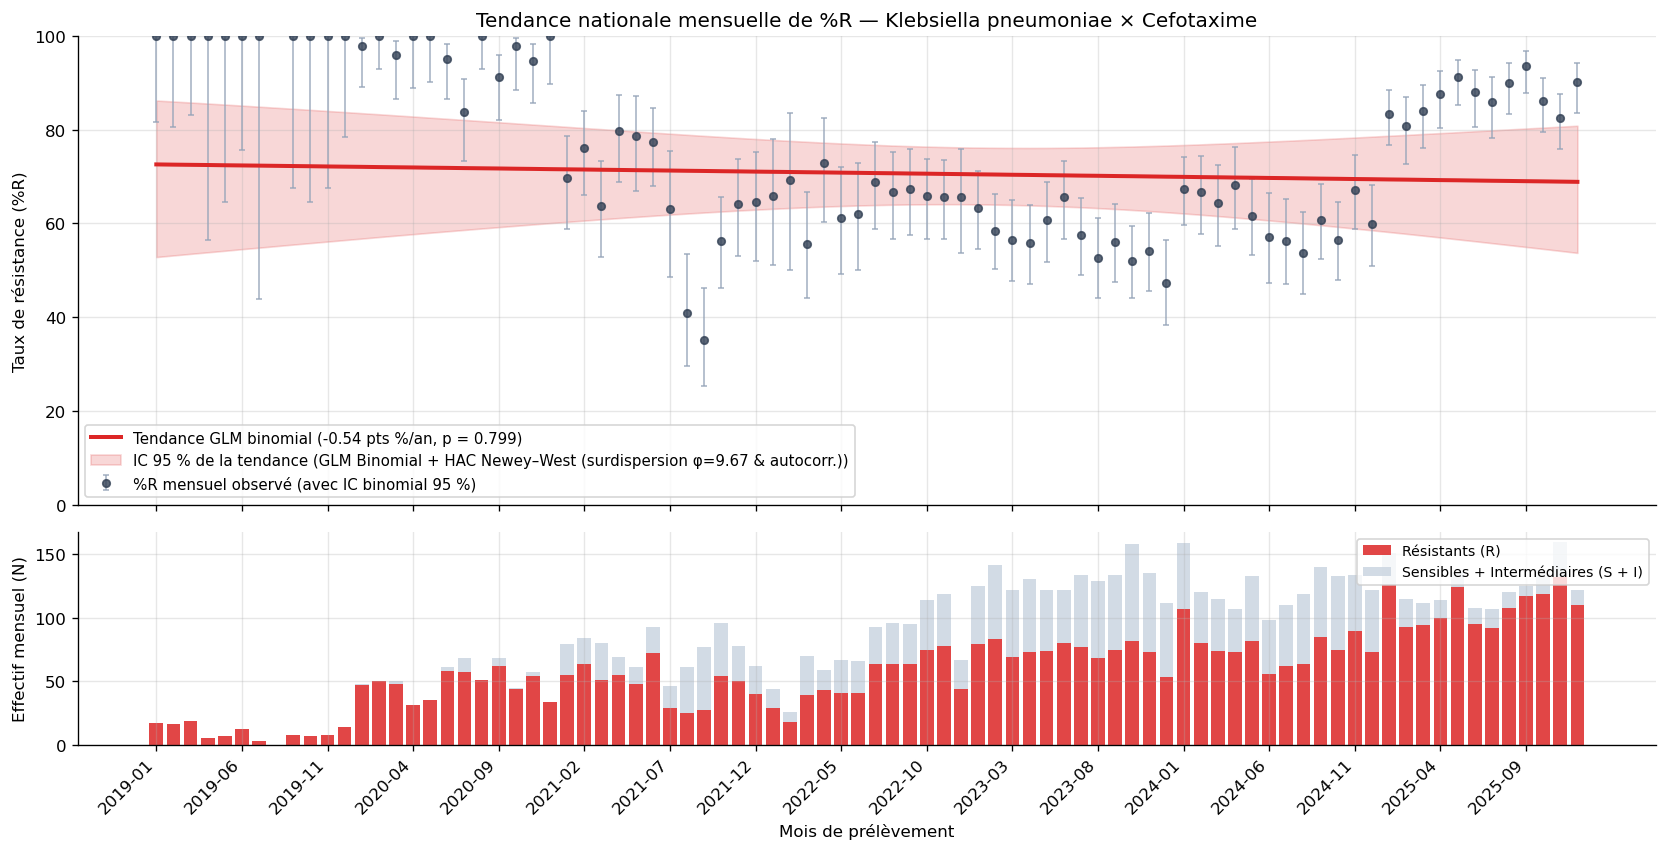

In [8]:
# 2.4.1 Analyse statistique et visualisation de la tendance nationale mensuelle pour le couple sélectionné
NATIONAL_MONTHLY_SIR_CUBE = build_national_monthly_sir_cube(filtered_source)

pair_monthly_obs = get_national_monthly_sir_series(
    NATIONAL_MONTHLY_SIR_CUBE,
    bacterie=TREND_BACTERIUM,
    antibiotique=TREND_ANTIBIOTIC,
    include_empty_months_as_nan=False,
)
pair_monthly_grid = get_national_monthly_sir_series(
    NATIONAL_MONTHLY_SIR_CUBE,
    bacterie=TREND_BACTERIUM,
    antibiotique=TREND_ANTIBIOTIC,
    include_empty_months_as_nan=True,
)

pair_trend_res = estimate_national_monthly_trend(
    pair_monthly_obs,
    min_months=MIN_TREND_MONTHS,
    min_total_n=LOW_COUNT_THRESHOLD,
)

print(f"=== TENDANCE NATIONALE MENSUELLE : {format_bacterium(TREND_BACTERIUM)} × {format_label(TREND_ANTIBIOTIC)} ===")
print(f"Statut du test               : {pair_trend_res['status']}")
if pair_trend_res.get("calculable"):
    diag = pair_trend_res["diagnostics"]
    print(f"Mois observés (N > 0)        : {pair_trend_res['n_months']} mois ({pair_trend_res['first_month']} -> {pair_trend_res['last_month']}, étendue = {pair_trend_res['span_years']:.2f} ans)")
    print(f"Effectif national cumulé R/N : {pair_trend_res['total_R']:,} / {pair_trend_res['total_N']:,} (%R global = {pair_trend_res['pooled_pct_R']:.2f}%)")
    print(f"Pente absolue (%R pts / an)  : {pair_trend_res['slope_pp_per_year']:+.2f} pts %/an (IC 95 % : [{pair_trend_res['slope_pp_ci_lower']:+.2f} ; {pair_trend_res['slope_pp_ci_upper']:+.2f}])")
    print(f"Échelle logit (modèle)       : β1 = {pair_trend_res['beta1_logit_per_year']:+.4f} log-odds/an | OR annuel = {pair_trend_res['or_per_year']:.3f} (IC 95 % : [{pair_trend_res['or_ci_lower']:.3f} ; {pair_trend_res['or_ci_upper']:.3f}])")
    print(f"Taux modélisé début -> fin   : {pair_trend_res['fitted_start_pct_R']:.1f}% -> {pair_trend_res['fitted_end_pct_R']:.1f}%")
    print(f"Diagnostics résiduels        : Dispersion φ = {diag['dispersion_phi']:.2f} (p = {diag['dispersion_pvalue']:.4f}) | Autocorr. r1 = {diag['lag1_autocorr']:.2f} | p Ljung-Box = {diag['ljung_box_pvalue']:.4f}")
    print(f"Méthode d'inférence retenue  : {pair_trend_res['inference_method']}")
    print(f"p-valeur robuste retenue     : {pair_trend_res['p_value']:.4g}")

    # Visualisation : Taux mensuels observés + IC binomiaux + Courbe de tendance GLM + Effectifs mensuels N_t
    fit_df = pair_trend_res["series_with_fit"]
    grid_df = pair_monthly_grid.merge(
        fit_df[["mois", "fitted_%R", "ci_lower_%R", "ci_upper_%R", "obs_ci_lower_%R", "obs_ci_upper_%R"]],
        on="mois",
        how="left",
    )
    x_idx = np.arange(len(grid_df))
    obs_mask = grid_df["N"] > 0

    fig, (ax1, ax2) = plt.subplots(
        2, 1, figsize=(14, 7.2), sharex=True, gridspec_kw={"height_ratios": [2.2, 1.0]}
    )

    # Barres d'erreur binomiales à 95 % (Wilson) et points observés pondérés visuellement par N_t
    y_obs = grid_df.loc[obs_mask, "%R"].to_numpy(dtype=float)
    y_err_low = y_obs - grid_df.loc[obs_mask, "obs_ci_lower_%R"].to_numpy(dtype=float)
    y_err_high = grid_df.loc[obs_mask, "obs_ci_upper_%R"].to_numpy(dtype=float) - y_obs
    ax1.errorbar(
        x_idx[obs_mask],
        y_obs,
        yerr=[ np.maximum(0, y_err_low), np.maximum(0, y_err_high) ],
        fmt="o",
        color="#334155",
        ecolor="#94a3b8",
        elinewidth=1.0,
        capsize=2,
        markersize=4.5,
        alpha=0.8,
        label="%R mensuel observé (avec IC binomial 95 %)",
    )

    # Courbe de tendance issue de la régression binomiale et bande d'IC à 95 %
    ax1.plot(
        x_idx[obs_mask],
        grid_df.loc[obs_mask, "fitted_%R"],
        color="#dc2626",
        linewidth=2.4,
        label=(
            f"Tendance GLM binomial ({pair_trend_res['slope_pp_per_year']:+.2f} pts %/an, "
            f"p = {pair_trend_res['p_value']:.3g})"
        ),
    )
    ax1.fill_between(
        x_idx[obs_mask],
        grid_df.loc[obs_mask, "ci_lower_%R"],
        grid_df.loc[obs_mask, "ci_upper_%R"],
        color="#dc2626",
        alpha=0.18,
        label=f"IC 95 % de la tendance ({pair_trend_res['inference_method']})",
    )

    ax1.set_ylim(0, 100)
    ax1.set_ylabel("Taux de résistance (%R)")
    ax1.set_title(
        f"Tendance nationale mensuelle de %R — {format_bacterium(TREND_BACTERIUM)} × {format_label(TREND_ANTIBIOTIC)}"
    )
    ax1.legend(loc="best", fontsize=9)

    # Panneau inférieur : effectifs mensuels R et S+I
    r_bars = grid_df["R"].to_numpy(dtype=float)
    si_bars = (grid_df["N"] - grid_df["R"]).to_numpy(dtype=float)
    ax2.bar(x_idx, r_bars, color="#dc2626", alpha=0.85, label="Résistants (R)")
    ax2.bar(x_idx, si_bars, bottom=r_bars, color="#cbd5e1", alpha=0.85, label="Sensibles + Intermédiaires (S + I)")
    ax2.set_ylabel("Effectif mensuel (N)")
    ax2.set_xlabel("Mois de prélèvement")
    ax2.legend(loc="upper right", fontsize=8.5)

    step = max(1, len(grid_df) // 16)
    ax2.set_xticks(range(0, len(grid_df), step))
    ax2.set_xticklabels(
        [grid_df["mois"].iloc[i] for i in range(0, len(grid_df), step)],
        rotation=45,
        ha="right",
    )
    plt.tight_layout()
    plt.show()

In [9]:
# 2.4.2 Tableau national des tendances pour tous les couples Bactérie × Antibiotique avec correction FDR (Benjamini–Hochberg)
FDR_ALPHA = 0.05

national_trends_df, trends_meta = analyze_all_national_trends(
    filtered_source,
    min_months=MIN_TREND_MONTHS,
    min_total_n=LOW_COUNT_THRESHOLD,
    fdr_alpha=FDR_ALPHA,
    format_bacterium_fn=format_bacterium,
    format_antibiotic_fn=format_label,
)

print("=== SYNTHÈSE DE LA FAMILLE DE TESTS ET CORRECTION DE BENJAMINI–HOCHBERG (FDR) ===")
print(f"Couples Bactérie × Antibiotique présents dans le périmètre : {trends_meta['n_pairs_total']}")
print(f"Famille de tests éligibles analysés (corrigés par FDR BH)  : {trends_meta['n_pairs_tested_fdr']} (critères : >= {trends_meta['min_months']} mois et N >= {trends_meta['min_total_n']})")
print(f"Couples non calculables (exclus de la famille FDR)         : {trends_meta['n_pairs_excluded']}")
print(f"Couples avec tendance significative après FDR (< {FDR_ALPHA:.0%})       : {trends_meta['n_significant_fdr']}")

cols_display_trend = [
    "Bactérie",
    "Antibiotique",
    "Mois observés",
    "Total R/N",
    "%R global",
    "Pente (%R pts/an)",
    "IC 95 % pente (pts/an)",
    "Pente logit (log-odds/an)",
    "OR annuel",
    "IC 95 % OR annuel",
    "p-valeur",
    "p-valeur FDR (BH)",
    "Direction / Interprétation",
    "Méthode d'inférence",
    "Dispersion (φ)",
]

calculable_trends = national_trends_df.loc[national_trends_df["Statut"] == "Calculé", cols_display_trend].reset_index(drop=True)
print("\n1. Couples avec les tendances nationales les plus marquées (triés par p-valeur FDR croissante, Top 25) :")
display(calculable_trends.head(25))

non_calculable_trends = national_trends_df.loc[
    national_trends_df["Statut"] != "Calculé",
    ["Bactérie", "Antibiotique", "Mois observés", "Total R/N", "%R global", "Statut"],
].reset_index(drop=True)
print(f"\n2. Aperçu des couples non calculables ({len(non_calculable_trends)} couples non soumis au test, avec motif explicite) :")
display(non_calculable_trends.head(15))

=== SYNTHÈSE DE LA FAMILLE DE TESTS ET CORRECTION DE BENJAMINI–HOCHBERG (FDR) ===
Couples Bactérie × Antibiotique présents dans le périmètre : 734
Famille de tests éligibles analysés (corrigés par FDR BH)  : 374 (critères : >= 6 mois et N >= 30)
Couples non calculables (exclus de la famille FDR)         : 360
Couples avec tendance significative après FDR (< 5%)       : 41

1. Couples avec les tendances nationales les plus marquées (triés par p-valeur FDR croissante, Top 25) :


,Bactérie,Antibiotique,Mois observés,Total R/N,%R global,Pente (%R pts/an),IC 95 % pente (pts/an),Pente logit (log-odds/an),OR annuel,IC 95 % OR annuel,p-valeur,p-valeur FDR (BH),Direction / Interprétation,Méthode d'inférence,Dispersion (φ)
0,Escherichia coli,Cefoxitin,67,"458 / 8,765",5.23,1.73,[+1.63 ; +1.83],0.3524,1.422,[1.395 ; 1.451],1.036702e-276,3.877266e-274,Hausse significative (FDR < 5%),GLM Quasi-Binomial (surdispersion φ=1.98),1.98
1,Escherichia coli,Ampicillin,60,"6,015 / 8,602",69.93,1.52,[+1.43 ; +1.60],0.0722,1.075,[1.071 ; 1.079],1.338461e-275,2.502923e-273,Hausse significative (FDR < 5%),GLM Quasi-Binomial (surdispersion φ=1.48),1.48
2,Klebsiella pneumoniae,Cefoxitin,67,"856 / 3,574",23.95,4.25,[+3.89 ; +4.61],0.2366,1.267,[1.241 ; 1.293],5.905922e-118,7.362716e-116,Hausse significative (FDR < 5%),GLM Quasi-Binomial (surdispersion φ=1.48),1.48
3,Escherichia coli,Ticarcillin,67,"6,100 / 8,988",67.87,1.58,[+1.44 ; +1.73],0.0728,1.076,[1.068 ; 1.083],2.129460e-107,1.991045e-105,Hausse significative (FDR < 5%),GLM Quasi-Binomial (surdispersion φ=1.63),1.63
4,Staphylococcus aureus,Benzylpenicillin,62,828 / 877,94.41,2.50,[+2.12 ; +2.88],0.4903,1.633,[1.526 ; 1.747],2.541801e-47,1.901267e-45,Hausse significative (FDR < 5%),GLM Quasi-Binomial (surdispersion φ=1.36),1.36
5,Pseudomonas aeruginosa,Colistin,63,215 / 598,35.95,-10.31,[-11.98 ; -8.65],-0.4803,0.619,[0.566 ; 0.676],1.131057e-27,7.050255e-26,Baisse significative (FDR < 5%),GLM Quasi-Binomial (surdispersion φ=1.56),1.56
6,Escherichia coli,Nalidixic acid,51,"1,100 / 3,517",31.28,-4.08,[-4.96 ; -3.21],-0.1913,0.826,[0.792 ; 0.861],1.915547e-20,1.023449e-18,Baisse significative (FDR < 5%),GLM Quasi-Binomial (surdispersion φ=1.48),1.48
7,Staphylococcus aureus,Trimethoprim/sulfamethoxazole,63,116 / 813,14.27,10.27,[+8.09 ; +12.45],0.9672,2.631,[2.104 ; 3.289],2.103051e-17,9.831764e-16,Hausse significative (FDR < 5%),GLM Binomial (MLE standard),1.12
8,Escherichia coli,Cefuroxime,50,"435 / 2,832",15.36,-1.92,[-2.41 ; -1.44],-0.1484,0.862,[0.831 ; 0.895],1.178486e-15,4.897264e-14,Baisse significative (FDR < 5%),GLM Quasi-Binomial (surdispersion φ=1.92),1.92
9,Staphylococcus aureus,Moxifloxacin,44,64 / 291,21.99,13.01,[+10.02 ; +16.00],0.8325,2.299,[1.862 ; 2.839],1.720551e-15,6.434859e-14,Hausse significative (FDR < 5%),GLM Quasi-Binomial (surdispersion φ=1.68),1.68



2. Aperçu des couples non calculables (360 couples non soumis au test, avec motif explicite) :


,Bactérie,Antibiotique,Mois observés,Total R/N,%R global,Statut
0,Enterobacter cloacae,Amoxicillin,67,459 / 459,100.00,Non calculé : résistance constante à 100 % (au...
1,Pseudomonas aeruginosa,Trimethoprim/sulfamethoxazole,42,75 / 75,100.00,Non calculé : résistance constante à 100 % (au...
2,Staphylococcus epidermidis,Tigecycline,22,0 / 73,0.00,Non calculé : résistance constante à 0 % (aucu...
3,Enterococcus faecalis,Daptomycin,23,0 / 72,0.00,Non calculé : résistance constante à 0 % (aucu...
4,Salmonella spp,Imipenem,34,0 / 72,0.00,Non calculé : résistance constante à 0 % (aucu...
5,Staphylococcus epidermidis,Minocycline,21,0 / 72,0.00,Non calculé : résistance constante à 0 % (aucu...
6,Salmonella spp,Cefoxitin,33,0 / 69,0.00,Non calculé : résistance constante à 0 % (aucu...
7,Enterococcus faecalis,Lincomycin,19,60 / 60,100.00,Non calculé : résistance constante à 100 % (au...
8,Escherichia coli,Kanamycin,3,6 / 56,10.71,Non calculé : nombre de mois insuffisant (3 < 6)
9,Pseudomonas aeruginosa,Cefotaxime,36,55 / 55,100.00,Non calculé : résistance constante à 100 % (au...


### 2.5 Comparaison descriptive des résistances entre Hôpitaux et entre Services

In [10]:
for col, label in ((HOSPITAL_COLUMN, "Hôpital"), (WARD_COLUMN, "Service")):
    comp = pooled_antibiotic_counts(
        trend_subset,
        [col],
        selected_trend_abx,
        records_frame=trend_records_subset,
    )
    comp[label] = fill_missing_label(comp[col])
    comp = comp.loc[comp["Testés (S/I/R)"] > 0].sort_values("Testés (S/I/R)", ascending=False).reset_index(drop=True)
    print(f"=== Comparaison par {label} ({format_bacterium(TREND_BACTERIUM)} × {format_label(TREND_ANTIBIOTIC)}) ===")
    display(comp[[label, "Résistants (R)", "Testés (S/I/R)", "S", "I", "%R"]].head(15))

=== Comparaison par Hôpital (Klebsiella pneumoniae × Cefotaxime) ===


,Hôpital,Résistants (R),Testés (S/I/R),S,I,%R
0,"La Rabta Hospital, Tunis",1311,1899,573,15,69.04
1,"Farhat Hached Hospital, Sousse",795,1812,1006,11,43.87
2,"Charles Nicolle Hospital, Tunis",1227,1516,285,4,80.94
3,"Fattouma Bourguiba University Hospital, Monastir",960,960,0,0,100.00
4,"Mohamed Kassab Orthopaedic Institute, Ksar Said",169,381,210,2,44.36
5,"Trauma and Burns Centre, Ben Arous",194,194,0,0,100.00
6,"Bechir Hamza Children's Hospital, Tunis",162,162,0,0,100.00
7,"Abderrahmen Mami Pneumo-phthisiology Hospital,...",127,127,0,0,100.00
8,"National Bone Marrow Transplant Centre, Tunis",29,29,0,0,100.00


=== Comparaison par Service (Klebsiella pneumoniae × Cefotaxime) ===


,Service,Résistants (R),Testés (S/I/R),S,I,%R
0,Non renseigné,2421,3679,1237,21,65.81
1,Paediatrics,503,538,35,0,93.49
2,Digestive and visceral surgery,410,439,26,3,93.39
3,Emergency medicine,252,414,161,1,60.87
4,Urological surgery,216,276,60,0,78.26
5,Medical intensive care,255,261,6,0,97.70
6,Nephrology,147,167,20,0,88.02
7,"Outpatient, external",37,146,108,1,25.34
8,Physical medicine and rehabilitation,58,142,83,1,40.85
9,Obstetrics and gynaecology,62,131,68,1,47.33


---
## 3. Forecasting Mensuel (`forecasting.py`)

Les séries mensuelles agrègent les résultats `S` et `R` sur l'ensemble des établissements (avec un seuil par défaut de `MIN_MONTHLY_TESTS = 3` tests par mois).
Six méthodes sont disponibles :
- `"naive"` : Prévision naïve (dernière valeur observée)
- `"holt"` : Lissage exponentiel double de Holt (niveau $\alpha$, tendance $\beta$)
- `"holt_winters"` : Holt-Winters additif saisonnier (période 12 mois, paramètres $\alpha, \beta, \gamma$)
- `"arima"` : ARIMA non-saisonnier (sélection automatique par AICc ou ordre manuel `(p, d, q)`)
- `"sarima"` : SARIMA saisonnier sur proportions transformées par logit (saisonnalité 12 mois, sélection AICc)
- `"binomial_glm"` : Régression binomiale temporelle pondérée par les effectifs mensuels `N = S + R`

In [11]:
# Construction du cube mensuel S/R à partir du périmètre dédupliqué actif
CUBE_MONTHLY = build_monthly_cube(filtered_source)
print(f"Points mensuels (bactérie × antibiotique × mois) : {len(CUBE_MONTHLY):,}")

# Paramètres de la prévision mensuelle
PRED_BACTERIUM = "Klebsiella pneumoniae"   # ou ALL_BACTERIA
PRED_ANTIBIOTIC = "Cefotaxime"             # ou ALL_ANTIBIOTICS
MONTHLY_HORIZON = 12                       # 6, 12 ou 24 mois
MONTHLY_METHOD = "holt"                    # "naive", "holt", "holt_winters", "arima", "sarima", "binomial_glm"
TRAINING_START_MONTH = None                # ex: "2019-01" (None = dès le premier mois)
TRAINING_END_MONTH = None                  # ex: "2024-12" (None = jusqu'au dernier mois)

Points mensuels (bactérie × antibiotique × mois) : 19,095


In [12]:
# Optimisation optionnelle des paramètres de lissage pour Holt / Holt-Winters
series_df, series_vals = get_monthly_resistance_series(
    CUBE_MONTHLY, PRED_BACTERIUM, PRED_ANTIBIOTIC
)

holt_alpha, holt_beta = 0.35, 0.12
hw_alpha, hw_beta, hw_gamma = 0.30, 0.10, 0.10

if len(series_vals) >= 24 + MONTHLY_HORIZON:
    opt_holt = optimize_holt_parameters(series_vals, validation_horizon=MONTHLY_HORIZON)
    holt_alpha, holt_beta = opt_holt["alpha"], opt_holt["beta"]
    print(f"Paramètres Holt optimisés : alpha={holt_alpha:.2f}, beta={holt_beta:.2f} (MAE validation={opt_holt['mae']:.2f}%)")

if len(series_vals) >= 36 + MONTHLY_HORIZON:
    opt_hw = optimize_holt_winters_parameters(series_vals, validation_horizon=MONTHLY_HORIZON)
    hw_alpha, hw_beta, hw_gamma = opt_hw["alpha"], opt_hw["beta"], opt_hw["gamma"]
    print(f"Paramètres Holt-Winters optimisés : alpha={hw_alpha:.2f}, beta={hw_beta:.2f}, gamma={hw_gamma:.2f} (MAE validation={opt_hw['mae']:.2f}%)")

Paramètres Holt optimisés : alpha=1.00, beta=0.00 (MAE validation=8.39%)


Paramètres Holt-Winters optimisés : alpha=0.50, beta=0.00, gamma=0.30 (MAE validation=8.84%)


Modèle retenu         : Holt
Période historique    : 2019-01 à 2025-12 (83 mois)
Dernier taux observé  : 90.2%
Prévision à +12 mois : 90.2%
Tendance annuelle     : +0.00% / an
Erreur MAE / RMSE     : 5.51% / 8.26%
Diagnostics résidus   : {'nombre de résidus': 83, 'test de Ljung–Box': None, 'note': 'Non calculé : des mois sans observation interrompent la série.'}


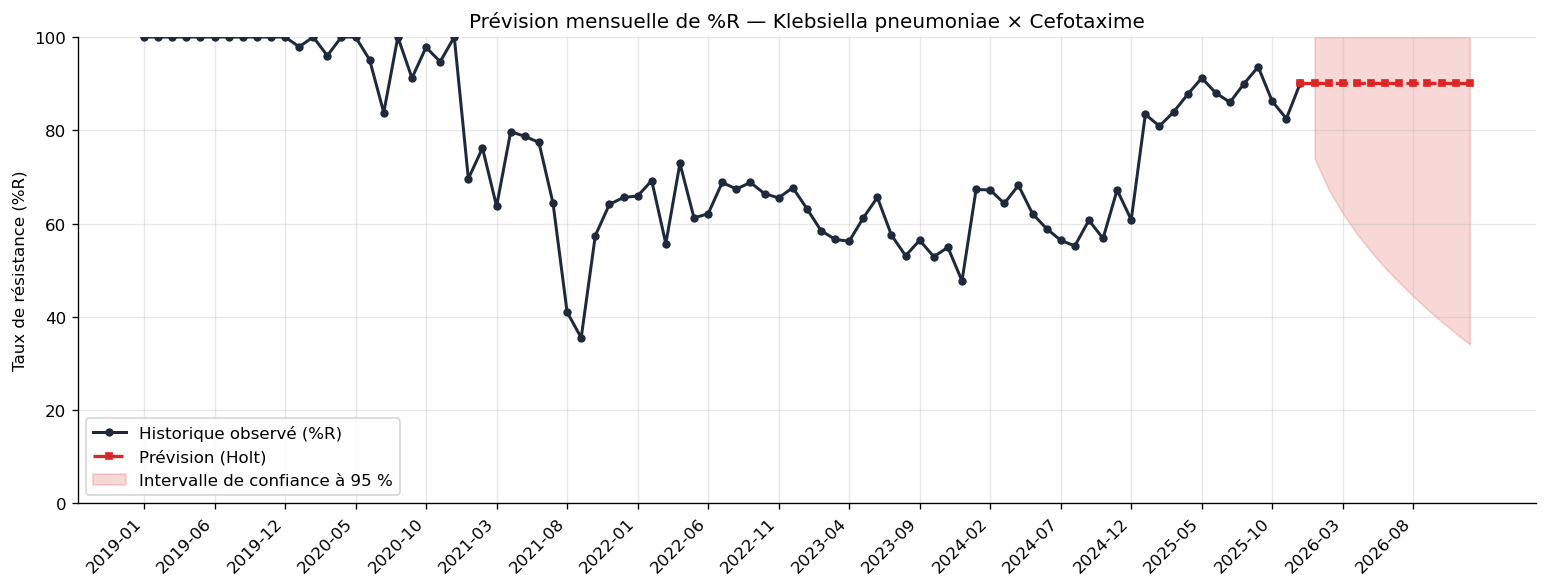

,Mois,Taux prédit (%R),IC inférieur (95 %),IC supérieur (95 %),N futur,IC observé inférieur,IC observé supérieur,Niveau de vigilance
0,2026-01,90.2,74.0,100.0,None,None,None,Critique (>50 %)
1,2026-02,90.2,67.3,100.0,None,None,None,Critique (>50 %)
2,2026-03,90.2,62.2,100.0,None,None,None,Critique (>50 %)
3,2026-04,90.2,57.8,100.0,None,None,None,Critique (>50 %)
4,2026-05,90.2,54.0,100.0,None,None,None,Critique (>50 %)
5,2026-06,90.2,50.5,100.0,None,None,None,Critique (>50 %)
6,2026-07,90.2,47.4,100.0,None,None,None,Critique (>50 %)
7,2026-08,90.2,44.4,100.0,None,None,None,Critique (>50 %)
8,2026-09,90.2,41.6,100.0,None,None,None,Critique (>50 %)
9,2026-10,90.2,39.0,100.0,None,None,None,Critique (>50 %)


In [13]:
# Exécution de la prévision mensuelle
monthly_forecast = run_monthly_forecast(
    CUBE_MONTHLY,
    bacterie=PRED_BACTERIUM,
    antibiotique=PRED_ANTIBIOTIC,
    horizon=MONTHLY_HORIZON,
    method=MONTHLY_METHOD,
    alpha=hw_alpha if MONTHLY_METHOD == "holt_winters" else holt_alpha,
    beta=hw_beta if MONTHLY_METHOD == "holt_winters" else holt_beta,
    gamma=hw_gamma,
    arima_auto=True,
    sarima_auto=True,
    glm_seasonal=True,
    training_start=TRAINING_START_MONTH,
    training_end=TRAINING_END_MONTH,
)

if monthly_forecast is None:
    print("Données mensuelles insuffisantes pour ce couple.")
else:
    print(f"Modèle retenu         : {monthly_forecast['method']}")
    print(f"Période historique    : {monthly_forecast['months'][0]} à {monthly_forecast['months'][-1]} ({len(monthly_forecast['months'])} mois)")
    print(f"Dernier taux observé  : {monthly_forecast['values'][-1]:.1f}%")
    print(f"Prévision à +{MONTHLY_HORIZON} mois : {monthly_forecast['future'][-1]['Taux prédit (%R)']:.1f}%")
    if monthly_forecast["trend_per_year"] is not None:
        print(f"Tendance annuelle     : {monthly_forecast['trend_per_year']:+.2f}% / an")
    print(f"Erreur MAE / RMSE     : {monthly_forecast['mae']:.2f}% / {monthly_forecast['rmse']:.2f}%")
    print(f"Diagnostics résidus   : {monthly_forecast['diagnostics']}")

    # Graphique Historique + Prévision + Intervalle de confiance à 95 %
    hist_months = monthly_forecast["months"]
    hist_vals = monthly_forecast["values"]
    fut_df = monthly_forecast["future_df"]
    fut_months = fut_df["Mois"].tolist()

    all_x = list(range(len(hist_months) + len(fut_months)))
    hist_x = list(range(len(hist_months)))
    fut_x = list(range(len(hist_months) - 1, len(hist_months) + len(fut_months)))

    fig, ax = plt.subplots(figsize=(13, 5))
    ax.plot(hist_x, hist_vals, label="Historique observé (%R)", color="#1e293b", marker="o", markersize=4, linewidth=1.8)
    ax.plot(
        fut_x,
        [hist_vals[-1]] + fut_df["Taux prédit (%R)"].tolist(),
        label=f"Prévision ({monthly_forecast['method']})",
        color="#dc2626",
        marker="s",
        markersize=4,
        linewidth=2,
        linestyle="--",
    )
    ax.fill_between(
        range(len(hist_months), len(hist_months) + len(fut_months)),
        fut_df["IC inférieur (95 %)"],
        fut_df["IC supérieur (95 %)"],
        color="#dc2626",
        alpha=0.18,
        label="Intervalle de confiance à 95 %",
    )

    labels = hist_months + fut_months
    step = max(1, len(labels) // 16)
    ax.set_xticks(range(0, len(labels), step))
    ax.set_xticklabels([labels[i] for i in range(0, len(labels), step)], rotation=45, ha="right")
    ax.set_ylim(0, 100)
    ax.set_ylabel("Taux de résistance (%R)")
    ax.set_title(f"Prévision mensuelle de %R — {format_bacterium(PRED_BACTERIUM)} × {format_label(PRED_ANTIBIOTIC)}")
    ax.legend()
    plt.tight_layout()
    plt.show()

    display(fut_df)

### 3.2 Comparaison des 5 méthodes mensuelles sur période de test chronologique

In [14]:
monthly_comparison_df = compare_monthly_methods_for_pair(
    CUBE_MONTHLY,
    bacterie=PRED_BACTERIUM,
    antibiotique=PRED_ANTIBIOTIC,
    horizon=MONTHLY_HORIZON,
    holt_alpha=holt_alpha,
    holt_beta=holt_beta,
    holt_winters_alpha=hw_alpha,
    holt_winters_beta=hw_beta,
    holt_winters_gamma=hw_gamma,
    training_start=TRAINING_START_MONTH,
    training_end=TRAINING_END_MONTH,
)
display(monthly_comparison_df)

,Méthode,MAE test (%),RMSE test (%),Observations test,Statut
0,Prévision naïve,None,None,12,Non calculée : la série mensuelle contient des...
1,ETS / Holt-Winters,None,None,12,Non calculée : la série mensuelle contient des...
2,ARIMA,None,None,12,Non calculée : la série mensuelle contient des...
3,SARIMA,None,None,12,Non calculée : la série mensuelle contient des...
4,Régression binomiale temporelle,None,None,12,Non calculée : la série mensuelle contient des...


---
## 4. Forecasting Trimestriel National & Comparaison de Méthodes (`quarterly_forecasting.py`)

L'agrégation trimestrielle nationale calcule $p_R = R / (S + I + R)$ sur un `PeriodIndex` trimestriel continu (`Q-DEC`). Les trimestres sans résultat restent `NaN` sans être imputés à 0 %.

Les 5 méthodes trimestrielles comparées sont :
1. **Prévision naïve** (`naive`, classique ou saisonnière de période 4)
2. **ETS / Holt-Winters** (`ets`, sur échelle logit ou directe)
3. **ARIMA** (`arima`, sélection d'ordre automatique par AICc sur chaque fenêtre d'apprentissage)
4. **SARIMA** (`sarima`, saisonnalité 4 trimestres, sélection automatique par AICc)
5. **Régression binomiale temporelle** (`binomial_glm`, GLM binomial pondéré par les effectifs trimestriels $N$)

In [15]:
# 4.1 Agrégation trimestrielle nationale sur la base dédupliquée active
QUARTERLY_BACTERIUM = "Klebsiella pneumoniae"  # ou None pour toutes les bactéries
QUARTERLY_ANTIBIOTIC = "Cefotaxime"            # ou None pour tous les antibiotiques
QUARTERLY_HORIZON = 4                          # Nombre de trimestres futurs à prédire
HOLDOUT_QUARTERS = 4                           # Trimestres finaux réservés pour le test hors-échantillon

quarterly_counts, quarterly_meta = aggregate_quarterly_counts(
    filtered_source,
    QUARTERLY_BACTERIUM,
    QUARTERLY_ANTIBIOTIC,
    low_n_threshold=30,
)

print(f"Couverture temporelle : {quarterly_meta['coverage_start']} -> {quarterly_meta['coverage_end']} ({quarterly_meta.get('quarter_count', 0)} trimestres)")
print(f"Total tests S/I/R     : N = {quarterly_meta.get('total_N', 0):,} (S={quarterly_meta.get('total_S', 0):,}, I={quarterly_meta.get('total_I', 0):,}, R={quarterly_meta.get('total_R', 0):,})")
print(f"Dates manquantes/invalides : {quarterly_meta['invalid_date_rows']:,}")
display(quarterly_counts.tail(12))

Couverture temporelle : 2019-01-01 -> 2025-12-31 (28 trimestres)
Total tests S/I/R     : N = 7,080 (S=2,074, I=32, R=4,974)
Dates manquantes/invalides : 0


_sir,S,I,R,N,p_R,low_n,boundary_incomplete,quarter_start,quarter_end
quarter,,,,,,,,,
2023Q1,158,0,231,389,0.593830,False,False,2023-01-01,2023-03-31
2023Q2,146,2,227,375,0.605333,False,False,2023-04-01,2023-06-30
2023Q3,175,2,220,397,0.554156,False,False,2023-07-01,2023-09-30
2023Q4,191,6,208,405,0.513580,False,False,2023-10-01,2023-12-31
2024Q1,132,1,261,394,0.662437,False,False,2024-01-01,2024-03-31
2024Q2,123,4,211,338,0.624260,False,False,2024-04-01,2024-06-30
2024Q3,155,3,211,369,0.571816,False,False,2024-07-01,2024-09-30
2024Q4,148,3,238,389,0.611825,False,False,2024-10-01,2024-12-31
2025Q1,65,0,313,378,0.828042,False,False,2025-01-01,2025-03-31


In [16]:
# 4.2 Configuration et exécution comparée des 5 méthodes trimestrielles
QUARTERLY_METHODS = {
    "Prévision naïve": "naive",
    "ETS / Holt-Winters": "ets",
    "ARIMA": "arima",
    "SARIMA": "sarima",
    "Régression binomiale temporelle": "binomial_glm",
}

# Effectif futur hypothétique par trimestre (médiane de la période d'apprentissage)
train_n = quarterly_counts.iloc[:-HOLDOUT_QUARTERS]["N"] if HOLDOUT_QUARTERS > 0 else quarterly_counts["N"]
scenario_future_n = max(1, int(round(train_n[train_n > 0].median())))
print(f"Scénario d'effectif futur par trimestre : N = {scenario_future_n:,}")

base_config = ForecastConfig(
    initial_window=min(12, max(4, len(quarterly_counts) - HOLDOUT_QUARTERS)),
    rolling_step=1,
    validation_horizons=(1, 2, 3, 4),
    window="growing",
    holdout_size=HOLDOUT_QUARTERS,
    seasonal_period=4,
    naive_seasonal=False,
    ets_trend="add",
    ets_seasonal="none",
    ets_smoothing_mode="automatic",
    arima_auto=True,
    sarima_auto=True,
    logit_transform=True,
    glm_trend="linear",
    glm_seasonal=False,
    future_n=scenario_future_n,
)

quarterly_results = {}
summary_rows = []

for label, method_code in QUARTERLY_METHODS.items():
    res = forecast_quarterly(
        quarterly_counts,
        method=method_code,
        horizon=QUARTERLY_HORIZON,
        config=base_config,
        future_n=scenario_future_n,
    )
    quarterly_results[method_code] = res
    val_m = res.get("validation_metrics", {})
    hold_m = res.get("holdout_metrics", {})
    summary_rows.append(
        {
            "Méthode": label,
            "Statut": res.get("status"),
            "MAE validation (pts %)": round(val_m["MAE"] * 100, 2) if val_m.get("MAE") is not None else None,
            "RMSE validation (pts %)": round(val_m["RMSE"] * 100, 2) if val_m.get("RMSE") is not None else None,
            "MAE test final (pts %)": round(hold_m["MAE"] * 100, 2) if hold_m.get("MAE") is not None else None,
            "RMSE test final (pts %)": round(hold_m["RMSE"] * 100, 2) if hold_m.get("RMSE") is not None else None,
            "Biais test final (pts %)": round(hold_m["bias"] * 100, 2) if hold_m.get("bias") is not None else None,
        }
    )

quarterly_comparison_df = pd.DataFrame(summary_rows).sort_values("MAE test final (pts %)", na_position="last").reset_index(drop=True)
print("=== Comparaison des performances trimestrielles (Validation glissante & Test final) ===")
display(quarterly_comparison_df)

Scénario d'effectif futur par trimestre : N = 230


=== Comparaison des performances trimestrielles (Validation glissante & Test final) ===


,Méthode,Statut,MAE validation (pts %),RMSE validation (pts %),MAE test final (pts %),RMSE test final (pts %),Biais test final (pts %)
0,Prévision naïve,ok,5.86,6.84,25.80,25.95,-25.80
1,ETS / Holt-Winters,ok,35.44,40.47,27.71,27.88,-27.71
2,SARIMA,ok,11.74,15.64,28.82,29.10,-28.82
3,ARIMA,ok,9.11,11.46,29.77,29.81,-29.77
4,Régression binomiale temporelle,ok,22.31,25.53,40.53,40.76,-40.53


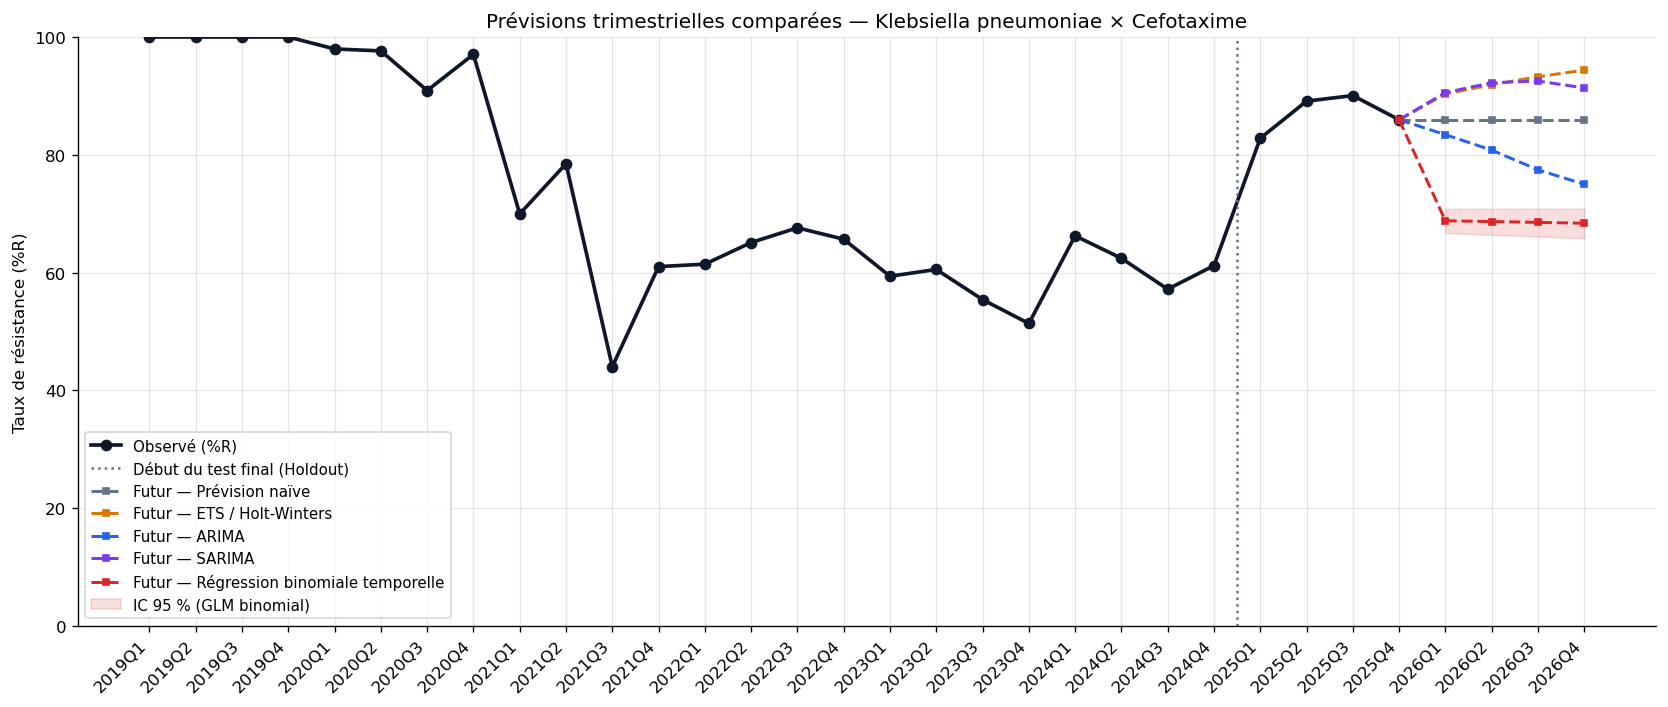

In [17]:
# 4.3 Visualisation comparée des prévisions trimestrielles (Test final + Horizon futur)
hist_quarters = quarterly_counts.index.astype(str).tolist()
hist_p_r = (quarterly_counts["p_R"] * 100).tolist()

first_ok = next((r for r in quarterly_results.values() if r.get("status") == "ok"), None)
if first_ok is not None:
    fut_quarters = first_ok["future"]["quarter"].astype(str).tolist()
    all_quarters = hist_quarters + fut_quarters

    fig, ax = plt.subplots(figsize=(14, 6))
    ax.plot(
        range(len(hist_quarters)),
        hist_p_r,
        label="Observé (%R)",
        color="#0f172a",
        marker="o",
        linewidth=2.2,
    )

    if HOLDOUT_QUARTERS > 0:
        split_idx = len(hist_quarters) - HOLDOUT_QUARTERS
        ax.axvline(split_idx - 0.5, color="#64748b", linestyle=":", linewidth=1.5, label="Début du test final (Holdout)")

    palette = {
        "naive": "#64748b",
        "ets": "#d97706",
        "arima": "#2563eb",
        "sarima": "#7c3aed",
        "binomial_glm": "#dc2626",
    }

    for label, method_code in QUARTERLY_METHODS.items():
        res = quarterly_results[method_code]
        if res.get("status") != "ok":
            continue
        fut_df = res["future"]
        fut_vals = (fut_df["forecast"] * 100).tolist()
        fut_x = list(range(len(hist_quarters) - 1, len(all_quarters)))
        ax.plot(
            fut_x,
            [hist_p_r[-1]] + fut_vals,
            marker="s",
            markersize=4,
            linestyle="--",
            linewidth=1.8,
            color=palette.get(method_code, None),
            label=f"Futur — {label}",
        )

    # Intervalle à 95 % pour le modèle GLM binomial (ou ARIMA)
    ref_res = quarterly_results.get("binomial_glm") or first_ok
    if ref_res and ref_res.get("status") == "ok":
        ref_fut = ref_res["future"]
        low_95 = ref_fut["lower"].combine_first(ref_fut.get("predictive_lower", pd.Series(dtype=float))) * 100
        high_95 = ref_fut["upper"].combine_first(ref_fut.get("predictive_upper", pd.Series(dtype=float))) * 100
        ax.fill_between(
            range(len(hist_quarters), len(all_quarters)),
            low_95,
            high_95,
            color="#dc2626",
            alpha=0.15,
            label="IC 95 % (GLM binomial)",
        )

    ax.set_xticks(range(len(all_quarters)))
    ax.set_xticklabels(all_quarters, rotation=45, ha="right")
    ax.set_ylim(0, 100)
    ax.set_ylabel("Taux de résistance (%R)")
    ax.set_title(
        f"Prévisions trimestrielles comparées — {format_bacterium(QUARTERLY_BACTERIUM)} × {format_label(QUARTERLY_ANTIBIOTIC)}"
    )
    ax.legend(loc="best", fontsize=9)
    plt.tight_layout()
    plt.show()

In [18]:
# 4.4 Tableau détaillé des prévisions futures trimestrielles par méthode
future_rows = []
for label, method_code in QUARTERLY_METHODS.items():
    res = quarterly_results[method_code]
    if res.get("status") != "ok":
        continue
    for _, row in res["future"].iterrows():
        future_rows.append(
            {
                "Méthode": label,
                "Trimestre": row["quarter"],
                "N futur supposé": int(row["future_n"]) if pd.notna(row.get("future_n")) else scenario_future_n,
                "Prévision (%R)": round(float(row["forecast"]) * 100, 2) if pd.notna(row.get("forecast")) else None,
                "IC modèle 95 % bas": round(float(row["lower"]) * 100, 2) if pd.notna(row.get("lower")) else None,
                "IC modèle 95 % haut": round(float(row["upper"]) * 100, 2) if pd.notna(row.get("upper")) else None,
                "IC observé binomial 95 % bas": (
                    round(float(row["predictive_lower"]) * 100, 2)
                    if pd.notna(row.get("predictive_lower"))
                    else None
                ),
                "IC observé binomial 95 % haut": (
                    round(float(row["predictive_upper"]) * 100, 2)
                    if pd.notna(row.get("predictive_upper"))
                    else None
                ),
            }
        )

future_quarterly_df = pd.DataFrame(future_rows)
display(future_quarterly_df)

,Méthode,Trimestre,N futur supposé,Prévision (%R),IC modèle 95 % bas,IC modèle 95 % haut,IC observé binomial 95 % bas,IC observé binomial 95 % haut
0,Prévision naïve,2026Q1,230,85.95,NaN,NaN,81.30,90.43
1,Prévision naïve,2026Q2,230,85.95,NaN,NaN,81.30,90.43
2,Prévision naïve,2026Q3,230,85.95,NaN,NaN,81.30,90.43
3,Prévision naïve,2026Q4,230,85.95,NaN,NaN,81.30,90.43
4,ETS / Holt-Winters,2026Q1,230,90.32,NaN,NaN,86.52,93.91
5,ETS / Holt-Winters,2026Q2,230,91.90,NaN,NaN,88.26,95.22
6,ETS / Holt-Winters,2026Q3,230,93.25,NaN,NaN,90.00,96.09
7,ETS / Holt-Winters,2026Q4,230,94.38,NaN,NaN,91.30,96.96
8,ARIMA,2026Q1,230,83.41,49.64,96.25,78.26,88.26
9,ARIMA,2026Q2,230,80.79,45.03,95.58,75.65,85.65
